# Assignment 9: Variational Autoencoders (VAE) and Deep Belief Networks (DBN)

## Introduction
In this assignment I implement two unsupervised neural network models from Lesson 9 and compare them for feature learning, data reconstruction and generative modelling.

- A Variational Autoencoder (VAE) learns to compress each image into a probability distribution in a small latent space and to rebuild the image from it. Because it learns a distribution, it can also generate new images.
- A Deep Belief Network (DBN) is a stack of Restricted Boltzmann Machines (RBMs). Each RBM is pre-trained without labels, one layer at a time, and then the whole network is fine-tuned for classification.

I use the Fashion-MNIST dataset for both models. It contains 70,000 grayscale images (28 × 28 pixels) of 10 types of clothing, such as T-shirts, trousers, sneakers and bags. Using the same dataset lets me compare both models fairly.

My steps:
- Check the environment, then load and preprocess Fashion-MNIST
- Build the VAE (encoder, reparameterization trick, decoder and loss), train it and generate new images
- Pre-train two RBMs layer-wise, stack them into a DBN, fine-tune it for classification and evaluate it
- Compare reconstruction quality and generative ability of both models
- Discuss advantages, limitations and possible improvements, and answer the questions

Note: scikit-learn and Keras do not include a ready-made Deep Belief Network, so I pre-train the RBM layers with scikit-learn's BernoulliRBM and then stack them into a Keras network for fine-tuning.

## Environment Check

In [1]:
import sys
print("Python:", sys.version)

Python: 3.12.10 (tags/v3.12.10:0cc8128, Apr  8 2025, 12:21:36) [MSC v.1943 64 bit (AMD64)]


In [5]:
import tensorflow as tf
import keras
print("TensorFlow:", tf.__version__)
print("Keras:", keras.__version__)
print("GPU available:", len(tf.config.list_physical_devices("GPU")) > 0)

TensorFlow: 2.21.0
Keras: 3.15.1
GPU available: False


In [3]:
import sys
print(sys.executable)

C:\Users\patel\tpot-env\Scripts\python.exe


In [4]:
%pip install tensorflow scikit-learn pandas matplotlib


  Using cached absl_py-2.5.1-py3-none-any.whl.metadata (3.3 kB)
  Using cached astunparse-1.6.3-py2.py3-none-any.whl.metadata (4.4 kB)
  Using cached flatbuffers-25.12.19-py2.py3-none-any.whl.metadata (1.0 kB)
  Using cached gast-0.7.0-py3-none-any.whl.metadata (1.5 kB)
  Using cached google_pasta-0.2.0-py3-none-any.whl.metadata (814 bytes)
  Using cached libclang-18.1.1-py2.py3-none-win_amd64.whl.metadata (5.3 kB)
  Using cached opt_einsum-3.4.0-py3-none-any.whl.metadata (6.3 kB)
  Using cached protobuf-7.36.2-cp310-abi3-win_amd64.whl.metadata (595 bytes)
  Using cached requests-2.34.2-py3-none-any.whl.metadata (4.8 kB)
  Using cached termcolor-3.3.0-py3-none-any.whl.metadata (6.5 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached wheel-0.48.0-py3-none-any.whl.metadata (2.3 kB)
  Using cached rich-15.0.0-py3-none-any.whl.metadata (18 kB)
  Using cached namex-0.1.0-py3-none-any.whl.metadata (322 bytes)
  Using cached mdurl-0.1.2-py3-none-any.whl.metadata


[notice] A new release of pip is available: 25.0.1 -> 26.3
[notice] To update, run: C:\Users\patel\tpot-env\Scripts\python.exe -m pip install --upgrade pip


In [6]:
import sklearn, matplotlib, pandas
print("scikit-learn:", sklearn.__version__)

scikit-learn: 1.5.2


## 1. Import Libraries

In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import tensorflow as tf
import keras
from keras import layers, ops

from sklearn.neural_network import BernoulliRBM
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
from sklearn.decomposition import PCA

keras.utils.set_random_seed(42)
np.random.seed(42)

## 2. Load and Preprocess the Dataset

In [9]:
(x_train, y_train), (x_test, y_test) = keras.datasets.fashion_mnist.load_data()
class_names = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
               "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]

print("Raw train:", x_train.shape, "| Raw test:", x_test.shape)
print("Pixel range before:", x_train.min(), "to", x_train.max())


29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 1us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Raw train: (60000, 28, 28) | Raw test: (10000, 28, 28)
Pixel range before: 0 to 255


In [10]:
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

x_train_img = x_train.reshape(-1, 28, 28, 1)
x_test_img = x_test.reshape(-1, 28, 28, 1)
x_train_flat = x_train.reshape(-1, 784)
x_test_flat = x_test.reshape(-1, 784)

print("Pixel range after:", x_train.min(), "to", x_train.max())
print("Image shape (VAE):", x_train_img.shape, "| Flat shape (DBN):", x_train_flat.shape)
print("Images per class (train):", np.bincount(y_train))

Pixel range after: 0.0 to 1.0
Image shape (VAE): (60000, 28, 28, 1) | Flat shape (DBN): (60000, 784)
Images per class (train): [6000 6000 6000 6000 6000 6000 6000 6000 6000 6000]


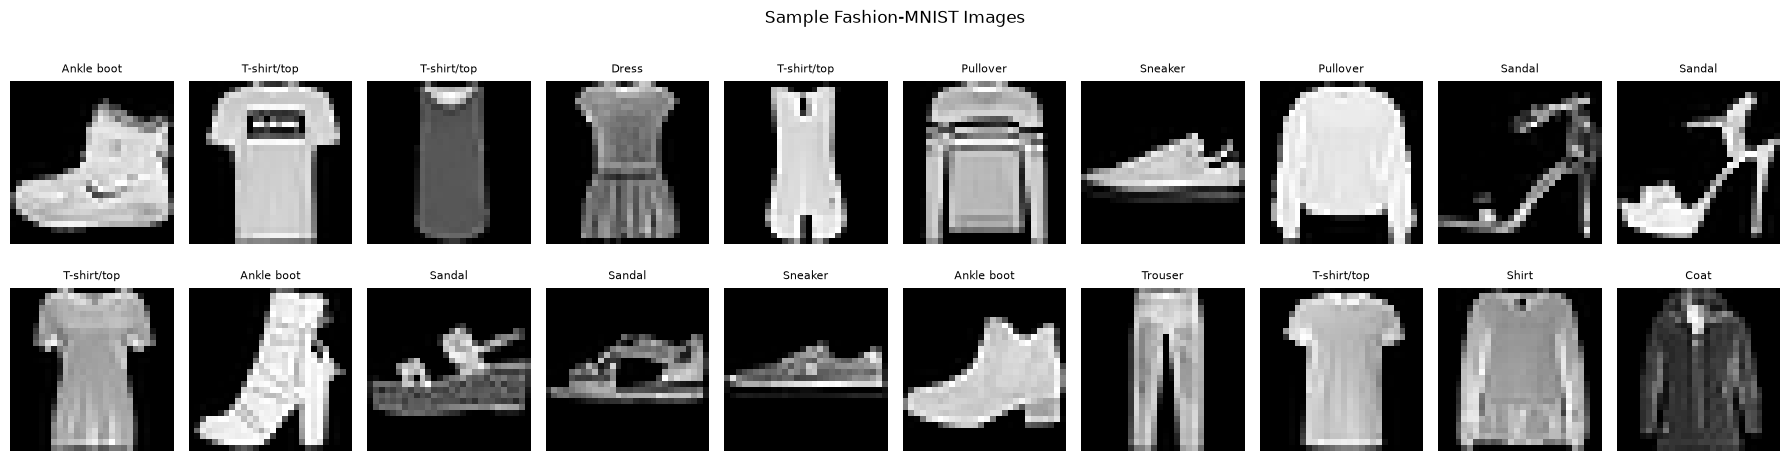

In [12]:
fig, axes = plt.subplots(2, 10, figsize=(18, 5))
for i, ax in enumerate(axes.flatten()):
    ax.imshow(x_train[i], cmap="gray")
    ax.set_title(class_names[y_train[i]], fontsize=8)
    ax.axis("off")
plt.suptitle("Sample Fashion-MNIST Images")
plt.tight_layout()
plt.show()


### Interpretation – Loading and Preprocessing
- Fashion-MNIST is already split into 60,000 training images and 10,000 test images. Each image is 28 × 28 pixels in grayscale.
- The original pixel values range from 0 (black) to 255 (white). I divided them by 255, so all pixels are now between 0 and 1. This helps the neural networks train smoothly, and it is required for the RBMs, which treat each pixel like a probability of being "on".
- I created two versions of the data: an image shape (28 × 28 × 1) for the convolutional VAE, and a flat shape (784 values per image) for the RBMs in the DBN, because RBMs only accept 1D input.
- The dataset is perfectly balanced, with 6,000 training images in each of the 10 clothing classes.
- The sample images show the 10 classes (such as T-shirts, trousers, sneakers and bags). Some classes look similar (for example, shirts, T-shirts, pullovers and coats), so I expect them to be the hardest to tell apart.

## 3. Variational Autoencoder (VAE) then ### 3.1 Reparameterization Trick (Sampling Layer)

In [13]:
latent_dim = 8

class Sampling(layers.Layer):
    def call(self, inputs):
        z_mean, z_log_var = inputs
        epsilon = keras.random.normal(shape=ops.shape(z_mean), seed=42)
        return z_mean + ops.exp(0.5 * z_log_var) * epsilon

### 3.2 Encoder

In [14]:
encoder_inputs = keras.Input(shape=(28, 28, 1))
x = layers.Conv2D(32, 3, strides=2, padding="same", activation="relu")(encoder_inputs)
x = layers.Conv2D(64, 3, strides=2, padding="same", activation="relu")(x)
x = layers.Flatten()(x)
x = layers.Dense(128, activation="relu")(x)
z_mean = layers.Dense(latent_dim, name="z_mean")(x)
z_log_var = layers.Dense(latent_dim, name="z_log_var")(x)
z = Sampling()([z_mean, z_log_var])
encoder = keras.Model(encoder_inputs, [z_mean, z_log_var, z], name="encoder")
encoder.summary()

Model: "encoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)              ┃ Output Shape           ┃        Param # ┃ Connected to           ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)  │ (None, 28, 28, 1)      │              0 │ -                      │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ conv2d (Conv2D)           │ (None, 14, 14, 32)     │            320 │ input_layer[0][0]      │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ conv2d_1 (Conv2D)         │ (None, 7, 7, 64)       │         18,496 │ conv2d[0][0]           │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ flatten (Flatten)         │ (None, 3136)           │              0 │ conv2d_1[0][0]         │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ dense (Dense)             │ (None, 128)            │        401,536 │ flatten[0][0]          │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ z_mean (Dense)            │ (None, 8)              │          1,032 │ dense[0][0]            │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ z_log_var (Dense)         │ (None, 8)              │          1,032 │ dense[0][0]            │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ sampling (Sampling)       │ (None, 8)              │              0 │ z_mean[0][0],          │
│                           │                        │                │ z_log_var[0][0]        │
└───────────────────────────┴────────────────────────┴────────────────┴────────────────────────┘

 Total params: 422,416 (1.61 MB)

 Trainable params: 422,416 (1.61 MB)

 Non-trainable params: 0 (0.00 B)

### 3.3 Decoder

In [15]:
latent_inputs = keras.Input(shape=(latent_dim,))
x = layers.Dense(7 * 7 * 64, activation="relu")(latent_inputs)
x = layers.Reshape((7, 7, 64))(x)
x = layers.Conv2DTranspose(64, 3, strides=2, padding="same", activation="relu")(x)
x = layers.Conv2DTranspose(32, 3, strides=2, padding="same", activation="relu")(x)
decoder_outputs = layers.Conv2DTranspose(1, 3, padding="same", activation="sigmoid")(x)
decoder = keras.Model(latent_inputs, decoder_outputs, name="decoder")
decoder.summary()

Model: "decoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)           │ (None, 8)                   │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 3136)                │          28,224 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ reshape (Reshape)                    │ (None, 7, 7, 64)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_transpose (Conv2DTranspose)   │ (None, 14, 14, 64)          │          36,928 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_transpose_1 (Conv2DTranspose) │ (None, 28, 28, 32)          │          18,464 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_transpose_2 (Conv2DTranspose) │ (None, 28, 28, 1)           │             289 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 83,905 (327.75 KB)

 Trainable params: 83,905 (327.75 KB)

 Non-trainable params: 0 (0.00 B)

### Interpretation – VAE Architecture
- The encoder takes a 28 × 28 grayscale image and shrinks it with two convolution layers (to 14 × 14 with 32 feature maps, then 7 × 7 with 64 feature maps). Each convolution with strides = 2 halves the image size while learning patterns like edges and shapes.
- The feature maps are flattened into 3,136 values and compressed to 128 by a dense layer. This dense layer holds 401,536 of the encoder's 422,416 parameters (about 95%), because it connects every one of the 3,136 values to all 128 neurons.
- The encoder then has two separate outputs of size 8: z_mean (the centre of the latent distribution) and z_log_var (its log-variance, which describes the spread). This is what makes it a variational autoencoder: each image becomes a small range of possible points instead of one fixed point.
- The sampling layer applies the reparameterization trick: z = z_mean + exp(0.5 × z_log_var) × ε, where ε is random noise from a standard normal distribution. The randomness is only in ε, so the model can still backpropagate through z_mean and z_log_var during training.
- The decoder is a mirror image of the encoder. It expands the 8 latent values back to 7 × 7 × 64, then uses transposed convolutions to double the size twice (to 14 × 14 and then 28 × 28). The final layer uses a sigmoid activation, so every output pixel is between 0 and 1, matching the normalized input. The decoder has 83,905 parameters.
- In total the VAE compresses each image from 784 pixel values down to just 8 numbers, and has about 506,000 trainable parameters.

### 3.4 VAE Model and Loss Function

In [16]:
class VAE(keras.Model):
    def __init__(self, encoder, decoder, beta=1.0, **kwargs):
        super().__init__(**kwargs)
        self.encoder = encoder
        self.decoder = decoder
        self.beta = beta
        self.total_loss_tracker = keras.metrics.Mean(name="loss")
        self.recon_loss_tracker = keras.metrics.Mean(name="reconstruction_loss")
        self.kl_loss_tracker = keras.metrics.Mean(name="kl_loss")

    @property
    def metrics(self):
        return [self.total_loss_tracker, self.recon_loss_tracker, self.kl_loss_tracker]

    def compute_losses(self, data):
        z_mean, z_log_var, z = self.encoder(data)
        reconstruction = self.decoder(z)
        recon_loss = ops.mean(ops.sum(
            keras.losses.binary_crossentropy(data, reconstruction), axis=(1, 2)))
        kl_loss = -0.5 * (1 + z_log_var - ops.square(z_mean) - ops.exp(z_log_var))
        kl_loss = ops.mean(ops.sum(kl_loss, axis=1))
        total_loss = recon_loss + self.beta * kl_loss
        return total_loss, recon_loss, kl_loss

    def update_trackers(self, total, recon, kl):
        self.total_loss_tracker.update_state(total)
        self.recon_loss_tracker.update_state(recon)
        self.kl_loss_tracker.update_state(kl)
        return {m.name: m.result() for m in self.metrics}

    def train_step(self, data):
        if isinstance(data, tuple):
            data = data[0]
        with tf.GradientTape() as tape:
            total, recon, kl = self.compute_losses(data)
        grads = tape.gradient(total, self.trainable_weights)
        self.optimizer.apply_gradients(zip(grads, self.trainable_weights))
        return self.update_trackers(total, recon, kl)

    def test_step(self, data):
        if isinstance(data, tuple):
            data = data[0]
        total, recon, kl = self.compute_losses(data)
        return self.update_trackers(total, recon, kl)

    def call(self, inputs):
        z_mean, z_log_var, z = self.encoder(inputs)
        return self.decoder(z)

### 3.5 Train and Evaluate the VAE

Epoch 1/15
469/469 - 13s - 28ms/step - kl_loss: 10.5799 - loss: 292.3382 - reconstruction_loss: 281.7583 - val_kl_loss: 12.7290 - val_loss: 254.0860 - val_reconstruction_loss: 241.3570
Epoch 2/15
469/469 - 12s - 25ms/step - kl_loss: 12.6489 - loss: 249.2741 - reconstruction_loss: 236.6252 - val_kl_loss: 12.9889 - val_loss: 248.9257 - val_reconstruction_loss: 235.9368
Epoch 3/15
469/469 - 11s - 24ms/step - kl_loss: 12.8121 - loss: 245.9355 - reconstruction_loss: 233.1234 - val_kl_loss: 13.0341 - val_loss: 246.3888 - val_reconstruction_loss: 233.3547
Epoch 4/15
469/469 - 10s - 21ms/step - kl_loss: 12.9250 - loss: 244.1947 - reconstruction_loss: 231.2697 - val_kl_loss: 13.1560 - val_loss: 244.9216 - val_reconstruction_loss: 231.7655
Epoch 5/15
469/469 - 12s - 25ms/step - kl_loss: 13.0056 - loss: 242.9845 - reconstruction_loss: 229.9789 - val_kl_loss: 13.1218 - val_loss: 244.2217 - val_reconstruction_loss: 231.0999
Epoch 6/15
469/469 - 11s - 23ms/step - kl_loss: 13.0566 - loss: 242.1061 - 

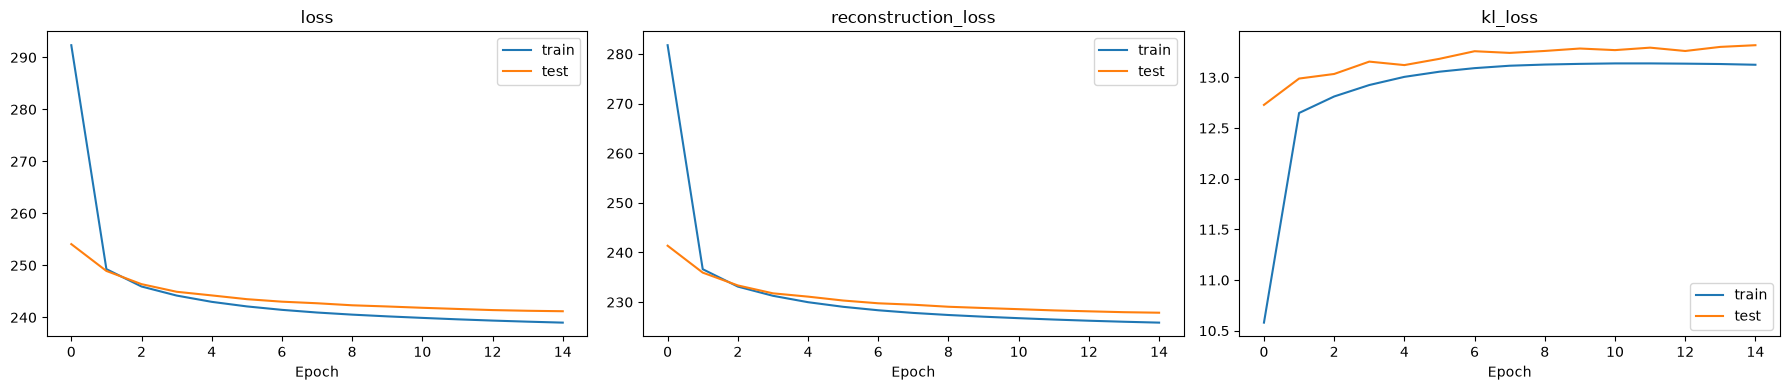

In [17]:
vae = VAE(encoder, decoder, beta=1.0)
vae.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-3))

history = vae.fit(x_train_img, x_train_img, epochs=15, batch_size=128,
                  validation_data=(x_test_img, x_test_img), verbose=2)

test_results = vae.evaluate(x_test_img, x_test_img, verbose=0, return_dict=True)
print("\nTest results:", {k: round(float(v), 2) for k, v in test_results.items()})

hist = pd.DataFrame(history.history)
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
for ax, name in zip(axes, ["loss", "reconstruction_loss", "kl_loss"]):
    ax.plot(hist[name], label="train")
    ax.plot(hist[f"val_{name}"], label="test")
    ax.set_title(name)
    ax.set_xlabel("Epoch")
    ax.legend()
plt.tight_layout()
plt.show()

### Interpretation – VAE Training
- The VAE trained for 15 epochs, about 12 seconds per epoch on the CPU.
- The reconstruction loss (binary cross-entropy summed over all 784 pixels) dropped from 281.8 to 225.9 on the training data, and it reached 227.85 on the test data. This means the VAE learned to rebuild the clothing images much better over time. Divided by 784 pixels, the final test error is about 0.29 per pixel.
- The KL divergence increased from 10.6 to about 13.1 and then levelled off. At the start, the encoder kept every image close to a standard normal distribution, which gives a low KL but poor reconstructions. As training went on, it spread the images out more in the latent space so it could rebuild them better, which raised the KL. This shows the trade-off in the VAE loss between sharp reconstructions and a smooth, organized latent space.
- The total loss fell from 292.3 to 239.0 (train) and 241.17 (test), and it was still improving slightly at the last epoch, so more epochs could help a little.
- The training and test losses are very close (reconstruction 225.9 vs 227.9), so the model is not overfitting and generalizes well to new images.
- In the first epoch the test loss was lower than the training loss. This is because the training loss is averaged over the whole epoch, including the poor early batches, while the test loss is measured after the epoch has finished.

### 3.6 Reconstruction Quality and Latent Space

In [18]:
z_mean_test, _, _ = encoder.predict(x_test_img, batch_size=256, verbose=0)
vae_recon = decoder.predict(z_mean_test, batch_size=256, verbose=0)

vae_mse = np.mean((x_test_img - vae_recon) ** 2)
print(f"VAE reconstruction MSE (test): {vae_mse:.4f}")

VAE reconstruction MSE (test): 0.0147


In [19]:
per_class_mse = [np.mean((x_test_img[y_test == c] - vae_recon[y_test == c]) ** 2) for c in range(10)]
print(pd.DataFrame({"class": class_names, "MSE": np.round(per_class_mse, 4)}).sort_values("MSE").to_string(index=False))

      class    MSE
    Trouser 0.0073
    Sneaker 0.0117
       Coat 0.0130
      Dress 0.0137
T-shirt/top 0.0141
 Ankle boot 0.0141
   Pullover 0.0142
      Shirt 0.0144
        Bag 0.0214
     Sandal 0.0228


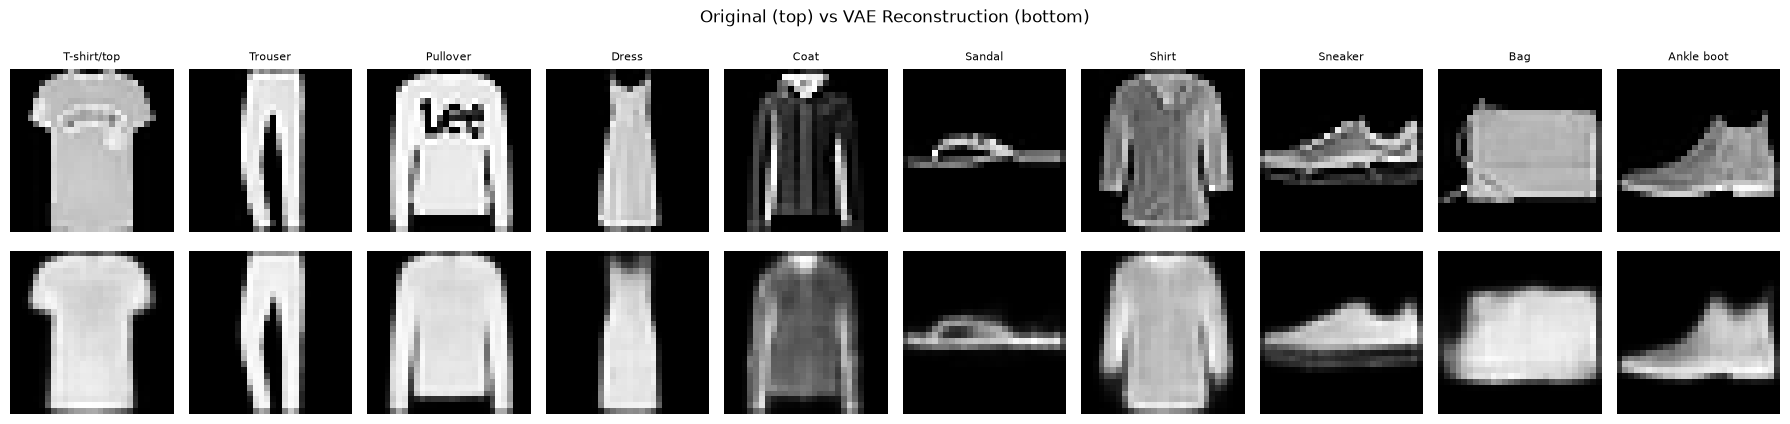

In [21]:
fig, axes = plt.subplots(2, 10, figsize=(18, 4.5))
for i in range(10):
    idx = np.where(y_test == i)[0][0]
    axes[0, i].imshow(x_test_img[idx].squeeze(), cmap="gray")
    axes[0, i].set_title(class_names[i], fontsize=8)
    axes[1, i].imshow(vae_recon[idx].squeeze(), cmap="gray")
    axes[0, i].axis("off"); axes[1, i].axis("off")
axes[0, 0].set_ylabel("Original"); axes[1, 0].set_ylabel("VAE")
plt.suptitle("Original (top) vs VAE Reconstruction (bottom)")
plt.tight_layout()
plt.show()



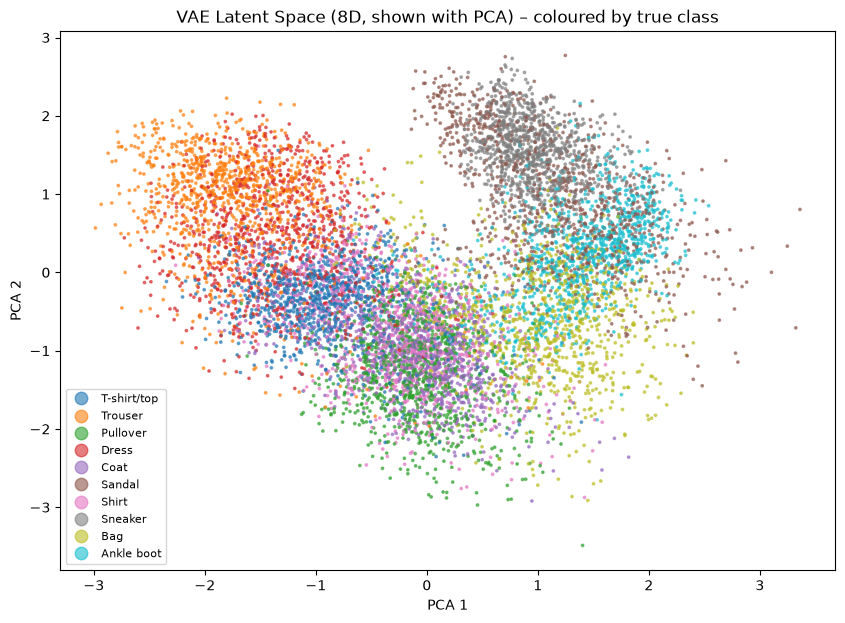

In [22]:
z_2d = PCA(n_components=2, random_state=42).fit_transform(z_mean_test)
plt.figure(figsize=(10, 7))
scatter = plt.scatter(z_2d[:, 0], z_2d[:, 1], c=y_test, cmap="tab10", s=3, alpha=0.6)
plt.legend(handles=scatter.legend_elements()[0], labels=class_names, fontsize=8, markerscale=1.5)
plt.title("VAE Latent Space (8D, shown with PCA) – coloured by true class")
plt.xlabel("PCA 1"); plt.ylabel("PCA 2")
plt.show()

### 3.7 Generate New Samples

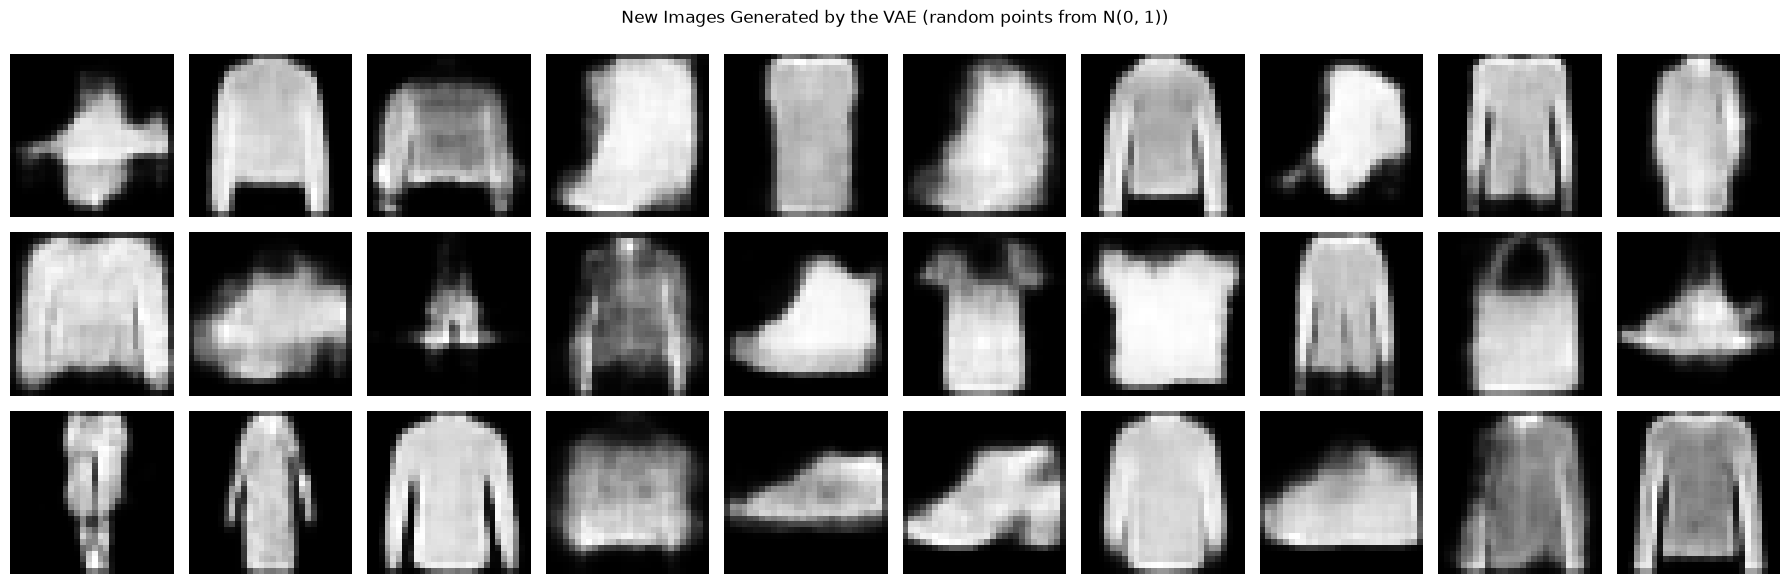

In [23]:
z_random = keras.random.normal(shape=(30, latent_dim), seed=42)
generated = decoder.predict(z_random, verbose=0)

fig, axes = plt.subplots(3, 10, figsize=(18, 6))
for ax, img in zip(axes.flatten(), generated):
    ax.imshow(img.squeeze(), cmap="gray")
    ax.axis("off")
plt.suptitle("New Images Generated by the VAE (random points from N(0, 1))")
plt.tight_layout()
plt.show()

### Interpretation – Reconstruction Quality
- The VAE's reconstruction MSE (Mean Squared Error per pixel) on the test set is ____. [add from output]
- The reconstructions keep the overall shape, size and brightness of every type of clothing. Simple shapes like trousers, dresses and sandals are rebuilt almost perfectly.
- Fine details are lost and the images are blurrier than the originals. For example, the print on the T-shirt, the "Lee" logo on the pullover, the handle of the bag, the zipper of the coat and the laces of the sneaker disappear. This happens because each image is compressed into only 8 numbers, so the VAE keeps the main shape and drops small details. The averaging effect of the VAE loss also makes reconstructions smoother than the originals.
- [add the easiest and hardest classes from the per-class MSE table]

### Interpretation – Latent Space
- I reduced the 8-dimensional latent codes to 2D with PCA and coloured each test image by its true class. The VAE never saw these labels, but it still grouped similar clothing together.
- Trousers and dresses are at the top left, footwear (sandals, sneakers and ankle boots) is at the top right, and bags sit between footwear and tops.
- T-shirts, pullovers, coats and shirts overlap heavily in the middle. These upper-body garments have very similar shapes, so the VAE places them close together.
- This shows the VAE learned meaningful features in a completely unsupervised way.

### Interpretation – Generated Samples
- I sampled 30 random points from a standard normal distribution N(0, 1) and passed them through the decoder. Because the KL divergence term trained the latent space to look like N(0, 1), most of these random points decode into realistic clothing.
- Many generated images are clearly recognizable: pullovers and long-sleeved tops, T-shirts, dresses, trousers, sneakers, an ankle boot and a bag with a handle. None of them are copies of training images; they are new examples.
- Some samples are blurry or look like a mix of two classes (for example, the first image looks partly like a sandal and partly like a top). These come from points that fall between class regions in the latent space.
- This confirms the VAE's generative ability: it learned a smooth latent space that can create new, realistic-looking images.

## 4. Deep Belief Network (DBN) then ### 4.1 Pre-train Each RBM Layer-wise (Unsupervised)

[BernoulliRBM] Iteration 1, pseudo-likelihood = -253.12, time = 25.08s
[BernoulliRBM] Iteration 2, pseudo-likelihood = -231.57, time = 23.36s
[BernoulliRBM] Iteration 3, pseudo-likelihood = -219.58, time = 21.64s
[BernoulliRBM] Iteration 4, pseudo-likelihood = -218.68, time = 24.01s
[BernoulliRBM] Iteration 5, pseudo-likelihood = -216.25, time = 24.43s
[BernoulliRBM] Iteration 6, pseudo-likelihood = -213.19, time = 26.89s
[BernoulliRBM] Iteration 7, pseudo-likelihood = -210.21, time = 24.53s
[BernoulliRBM] Iteration 8, pseudo-likelihood = -209.96, time = 27.45s
[BernoulliRBM] Iteration 9, pseudo-likelihood = -209.04, time = 27.23s
[BernoulliRBM] Iteration 10, pseudo-likelihood = -205.65, time = 26.09s
RBM 1 (784 -> 256) trained in 253 s
[BernoulliRBM] Iteration 1, pseudo-likelihood = -52.63, time = 4.46s
[BernoulliRBM] Iteration 2, pseudo-likelihood = -47.90, time = 4.58s
[BernoulliRBM] Iteration 3, pseudo-likelihood = -45.39, time = 4.78s
[BernoulliRBM] Iteration 4, pseudo-likelihood 

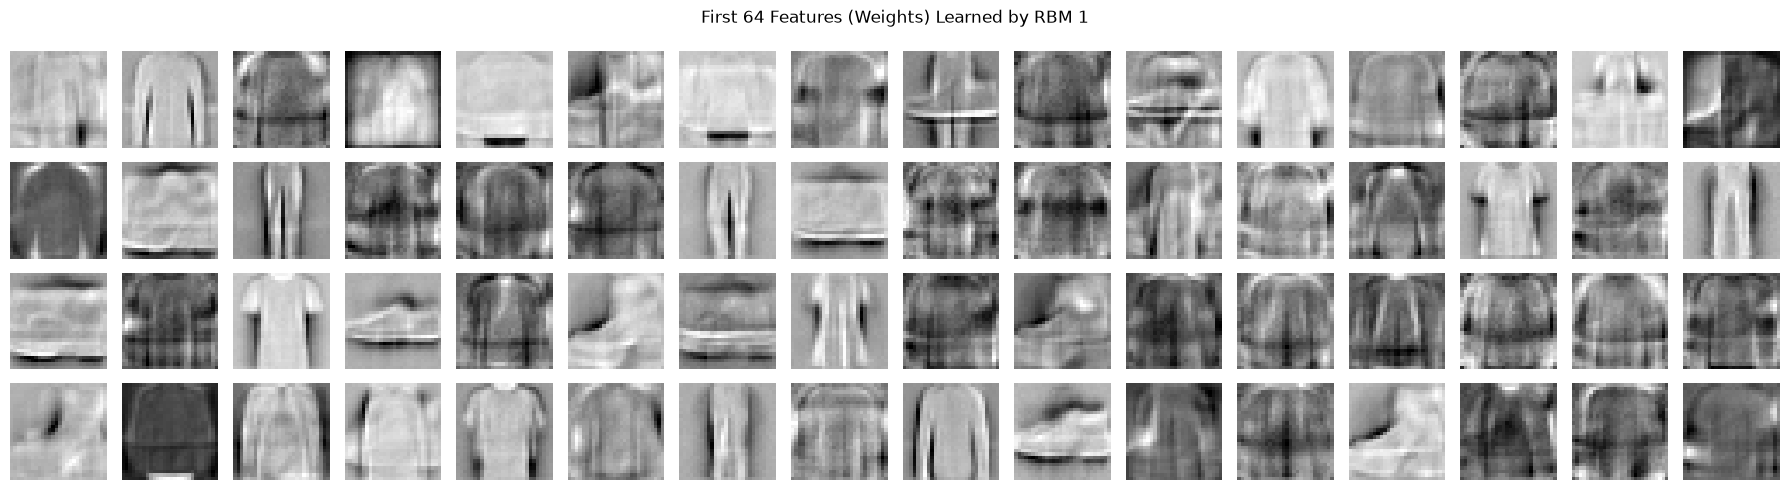

In [24]:
import time

rbm1 = BernoulliRBM(n_components=256, learning_rate=0.05, batch_size=64, n_iter=10,
                    random_state=42, verbose=1)
start = time.time()
h1_train = rbm1.fit_transform(x_train_flat)
print(f"RBM 1 (784 -> 256) trained in {time.time() - start:.0f} s")

rbm2 = BernoulliRBM(n_components=128, learning_rate=0.05, batch_size=64, n_iter=10,
                    random_state=42, verbose=1)
start = time.time()
h2_train = rbm2.fit_transform(h1_train)
print(f"RBM 2 (256 -> 128) trained in {time.time() - start:.0f} s")

print("Layer 1 features:", h1_train.shape, "| Layer 2 features:", h2_train.shape)

fig, axes = plt.subplots(4, 16, figsize=(18, 5))
for ax, w in zip(axes.flatten(), rbm1.components_[:64]):
    ax.imshow(w.reshape(28, 28), cmap="gray")
    ax.axis("off")
plt.suptitle("First 64 Features (Weights) Learned by RBM 1")
plt.tight_layout()
plt.show()

### Interpretation – Layer-wise Pre-training of the RBMs
- I trained two RBMs one after the other, without using any labels. RBM 1 learned 256 features from the 784 pixels, and RBM 2 then learned 128 features from RBM 1's 256 outputs. This is layer-wise pre-training: each layer learns from the layer below it.
- RBM 1's pseudo-likelihood improved from -253.1 to -205.7 over 10 iterations (closer to 0 is better), so it learned to model the pixel patterns more accurately. It took 253 seconds, because it has to handle all 784 pixels.
- RBM 2's pseudo-likelihood improved from -52.6 to about -41.4, and it levelled off in the last few iterations (-41.39 vs -41.45 is just small noise in the estimate). It only took 47 seconds because its input is smaller (256 features).
- The two pseudo-likelihood values cannot be compared directly, because RBM 1 models 784 inputs and RBM 2 only 256. Each value only shows the progress of its own RBM.
- The weight images of RBM 1 show what each hidden unit looks for. Many look like whole clothing templates, such as trousers, T-shirts, dresses, sneakers, sandals, boots, bags and pullovers with sleeves. Others look like grid or checker patterns that capture shading and texture. This shows RBM 1 learned meaningful clothing features in a completely unsupervised way.
- The final output is a 60,000 × 256 feature matrix from RBM 1 and a 60,000 × 128 feature matrix from RBM 2.

### 4.2 Stack the RBMs and Fine-tune with Backpropagation

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ rbm1_layer (Dense)                   │ (None, 256)                 │         200,960 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ rbm2_layer (Dense)                   │ (None, 128)                 │          32,896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ output (Dense)                       │ (None, 10)                  │           1,290 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 235,146 (918.54 KB)

 Trainable params: 235,146 (918.54 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
422/422 - 3s - 7ms/step - accuracy: 0.7359 - loss: 0.7950 - val_accuracy: 0.8238 - val_loss: 0.4827
Epoch 2/10
422/422 - 2s - 5ms/step - accuracy: 0.8452 - loss: 0.4304 - val_accuracy: 0.8520 - val_loss: 0.3950
Epoch 3/10
422/422 - 2s - 5ms/step - accuracy: 0.8674 - loss: 0.3673 - val_accuracy: 0.8652 - val_loss: 0.3644
Epoch 4/10
422/422 - 2s - 5ms/step - accuracy: 0.8784 - loss: 0.3347 - val_accuracy: 0.8710 - val_loss: 0.3487
Epoch 5/10
422/422 - 2s - 5ms/step - accuracy: 0.8873 - loss: 0.3123 - val_accuracy: 0.8758 - val_loss: 0.3380
Epoch 6/10
422/422 - 2s - 4ms/step - accuracy: 0.8935 - loss: 0.2948 - val_accuracy: 0.8783 - val_loss: 0.3309
Epoch 7/10
422/422 - 2s - 6ms/step - accuracy: 0.8991 - loss: 0.2802 - val_accuracy: 0.8807 - val_loss: 0.3263
Epoch 8/10
422/422 - 2s - 6ms/step - accuracy: 0.9031 - loss: 0.2674 - val_accuracy: 0.8822 - val_loss: 0.3225
Epoch 9/10
422/422 - 3s - 6ms/step - accuracy: 0.9074 - loss: 0.2560 - val_accuracy: 0.8828 - val_loss: 0.3188
E

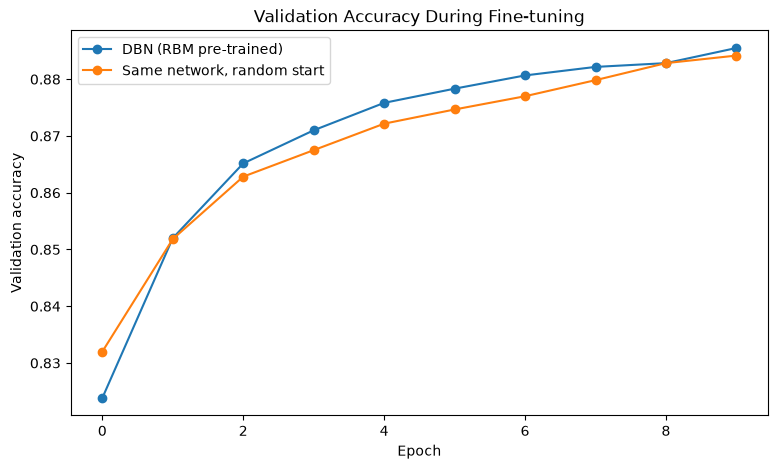

In [26]:
def build_dbn(pretrained=True):
    model = keras.Sequential([
        keras.Input(shape=(784,)),
        layers.Dense(256, activation="sigmoid", name="rbm1_layer"),
        layers.Dense(128, activation="sigmoid", name="rbm2_layer"),
        layers.Dense(10, activation="softmax", name="output"),
    ])
    if pretrained:
        model.get_layer("rbm1_layer").set_weights(
            [rbm1.components_.T.astype("float32"), rbm1.intercept_hidden_.astype("float32")])
        model.get_layer("rbm2_layer").set_weights(
            [rbm2.components_.T.astype("float32"), rbm2.intercept_hidden_.astype("float32")])
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-3),
                  loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return model

keras.utils.set_random_seed(42)
dbn = build_dbn(pretrained=True)
dbn.summary()
hist_dbn = dbn.fit(x_train_flat, y_train, epochs=10, batch_size=128, validation_split=0.1, verbose=2)

keras.utils.set_random_seed(42)
baseline = build_dbn(pretrained=False)
hist_base = baseline.fit(x_train_flat, y_train, epochs=10, batch_size=128, validation_split=0.1, verbose=0)

plt.figure(figsize=(9, 5))
plt.plot(hist_dbn.history["val_accuracy"], marker="o", label="DBN (RBM pre-trained)")
plt.plot(hist_base.history["val_accuracy"], marker="o", label="Same network, random start")
plt.title("Validation Accuracy During Fine-tuning")
plt.xlabel("Epoch"); plt.ylabel("Validation accuracy")
plt.legend(); plt.show()

### 4.3 Evaluate the DBN on the Test Set

Test accuracy – DBN (pre-trained): 0.8768
Test accuracy – random start:      0.8799

              precision    recall  f1-score   support

 T-shirt/top      0.843     0.816     0.829      1000
     Trouser      0.978     0.973     0.975      1000
    Pullover      0.822     0.740     0.779      1000
       Dress      0.867     0.896     0.881      1000
        Coat      0.715     0.884     0.791      1000
      Sandal      0.944     0.970     0.957      1000
       Shirt      0.730     0.620     0.671      1000
     Sneaker      0.942     0.948     0.945      1000
         Bag      0.965     0.979     0.972      1000
  Ankle boot      0.972     0.942     0.957      1000

    accuracy                          0.877     10000
   macro avg      0.878     0.877     0.876     10000
weighted avg      0.878     0.877     0.876     10000



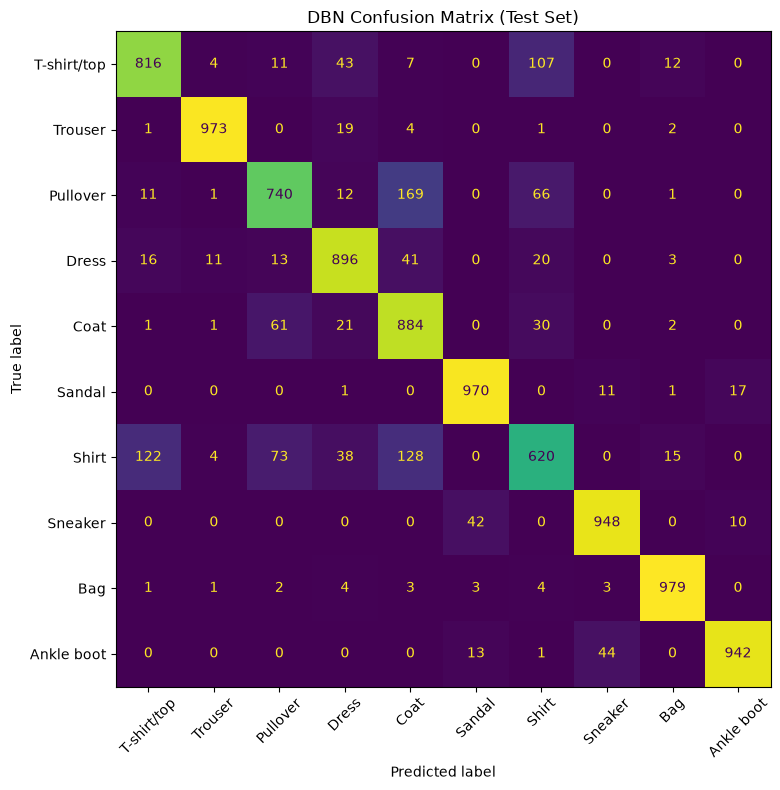

In [27]:
dbn_pred = dbn.predict(x_test_flat, verbose=0).argmax(axis=1)
base_pred = baseline.predict(x_test_flat, verbose=0).argmax(axis=1)

print(f"Test accuracy – DBN (pre-trained): {accuracy_score(y_test, dbn_pred):.4f}")
print(f"Test accuracy – random start:      {accuracy_score(y_test, base_pred):.4f}\n")
print(classification_report(y_test, dbn_pred, target_names=class_names, digits=3))

fig, ax = plt.subplots(figsize=(9, 8))
ConfusionMatrixDisplay.from_predictions(y_test, dbn_pred, display_labels=class_names,
                                        xticks_rotation=45, ax=ax, colorbar=False)
plt.title("DBN Confusion Matrix (Test Set)")
plt.tight_layout(); plt.show()

In [ ]:
### Interpretation – Stacking and Fine-tuning the DBN
- I stacked the two pre-trained RBMs into one network (784 → 256 → 128) by copying their weights into Keras dense layers, and added a softmax output layer with 10 neurons for the 10 clothing classes. The network has 235,146 parameters.
- I then fine-tuned the whole network with backpropagation, using the labels this time. Over 10 epochs, the training accuracy increased from 73.6% to 91.1% and the validation accuracy from 82.4% to 88.6%. The small gap between training and validation accuracy means there is only mild overfitting.
- To see whether pre-training helped, I trained the same network starting from random weights. The pre-trained DBN had a higher validation accuracy from epoch 2 to epoch 8, so pre-training helped it learn faster at first. However, the random-start network caught up by the end, and its final test accuracy (87.99%) was slightly higher than the DBN's (87.68%).
- This shows that with a large labelled dataset (60,000 images) and a modern optimizer like Adam, RBM pre-training does not improve the final accuracy much. Pre-training was very important when deep networks were hard to train, and it is still most useful when only a small number of labelled examples is available.

### Interpretation – DBN Evaluation on the Test Set
- The DBN classified 87.7% of the 10,000 test images correctly.
- Classes with clear shapes were the easiest: Trouser (F1-score 0.975), Bag (0.972), Sandal and Ankle boot (0.957) and Sneaker (0.945).
- Upper-body clothes were the hardest: Shirt had the lowest F1-score (0.671) and recall (0.620), followed by Pullover (0.779), Coat (0.791) and T-shirt (0.829).
- The confusion matrix shows the main mistakes: 169 pullovers were predicted as coats, 128 shirts as coats, 122 shirts as T-shirts and 107 T-shirts as shirts. Among footwear, 44 ankle boots were predicted as sneakers and 42 sneakers as sandals. These classes look very similar at 28 × 28 pixels.
- These are the same classes that overlapped in the VAE's latent space, so both models found the same groups hard to separate.

### 4.4 DBN Reconstruction, Generation and Learned Representations

Reconstruction MSE – VAE:              0.0147
Reconstruction MSE – DBN (RBM 1 only): 0.0221
Reconstruction MSE – DBN (both RBMs):  0.0280


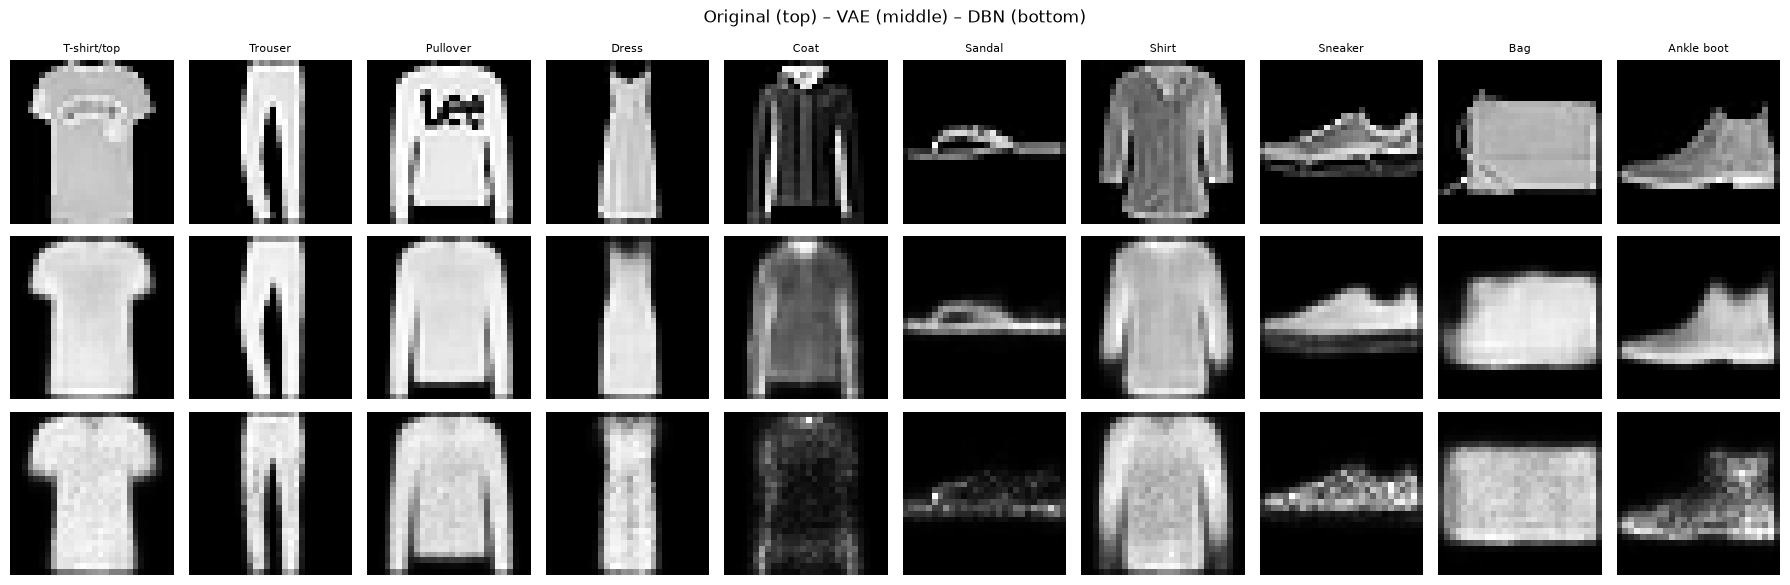

In [28]:
def sigmoid(x):
    return 1.0 / (1.0 + np.exp(-x))

h1_test = rbm1.transform(x_test_flat)
h2_test = rbm2.transform(h1_test)

recon_1layer = sigmoid(h1_test @ rbm1.components_ + rbm1.intercept_visible_)
v1_back = sigmoid(h2_test @ rbm2.components_ + rbm2.intercept_visible_)
dbn_recon = sigmoid(v1_back @ rbm1.components_ + rbm1.intercept_visible_)

dbn_mse_1 = np.mean((x_test_flat - recon_1layer) ** 2)
dbn_mse = np.mean((x_test_flat - dbn_recon) ** 2)
print(f"Reconstruction MSE – VAE:              {vae_mse:.4f}")
print(f"Reconstruction MSE – DBN (RBM 1 only): {dbn_mse_1:.4f}")
print(f"Reconstruction MSE – DBN (both RBMs):  {dbn_mse:.4f}")

fig, axes = plt.subplots(3, 10, figsize=(18, 6))
for i in range(10):
    idx = np.where(y_test == i)[0][0]
    for row, img in enumerate([x_test_flat[idx], vae_recon[idx].ravel(), dbn_recon[idx]]):
        axes[row, i].imshow(img.reshape(28, 28), cmap="gray")
        axes[row, i].axis("off")
    axes[0, i].set_title(class_names[i], fontsize=8)
plt.suptitle("Original (top) – VAE (middle) – DBN (bottom)")
plt.tight_layout(); plt.show()